In [30]:
# load dependencies
import numpy as np
import pandas as pd
import skgstat as skg
import xarray as xr
from sklearn.preprocessing import QuantileTransformer
from skgstat import models
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import LightSource
import gstatsim as gs
import random

In [7]:
# import data
ds = xr.open_dataset('Data/BedMachineAntarctica-v3.nc')

In [68]:
# set coordinates (in polar stereographic units)
xmin = -1673_250
xmax = -955_250
ymin = -1277_250
ymax = -505_250

x_slice = slice(xmin, xmax) if ds.x[0] < ds.x[-1] else slice(xmax, xmin)
y_slice = slice(ymin, ymax) if ds.y[0] < ds.y[-1] else slice(ymax, ymin)
mbl = ds.sel(x=x_slice, y=y_slice)
mbl

<xarray.Dataset> Size: 55MB
Dimensions:    (y: 1544, x: 1436)
Coordinates:
  * y          (y) int32 6kB -505500 -506000 -506500 ... -1276500 -1277000
  * x          (x) int32 6kB -1673000 -1672500 -1672000 ... -956000 -955500
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 2MB ...
    firn       (y, x) float32 9MB ...
    surface    (y, x) float32 9MB ...
    thickness  (y, x) float32 9MB ...
    bed        (y, x) float32 9MB ...
    errbed     (y, x) float32 9MB ...
    source     (y, x) int8 2MB ...
    dataid     (y, x) int8 2MB ...
    geoid      (y, x) int16 4MB ...
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

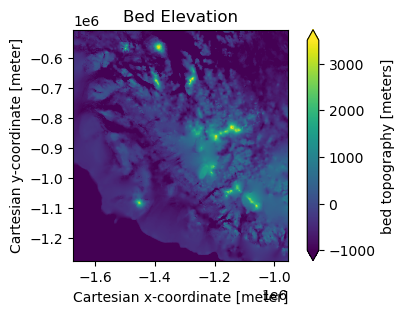

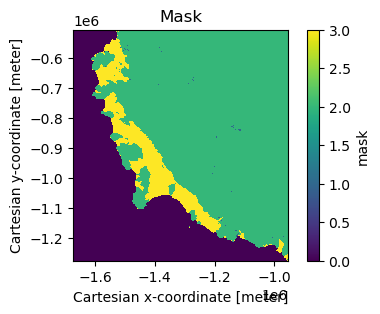

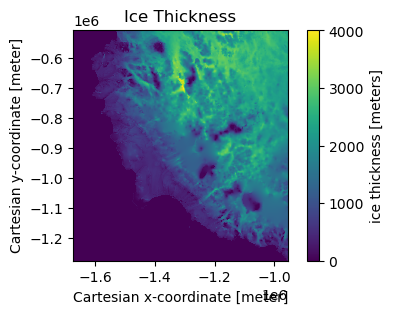

In [69]:
#initial Pots from Bedmachine3

#Plot bed elevation
fig, ax = plt.subplots(figsize=(5, 3))
mbl["bed"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True, vmin = -1000, vmax = 3500)
ax.set_title("Bed Elevation")
ax.set_aspect("equal")
plt.show()

#Plot Mask
fig, ax = plt.subplots(figsize=(5, 3))
mbl["mask"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True,)
ax.set_title("Mask")
ax.set_aspect("equal")
plt.show()

#Plot Ice Thickness
fig, ax = plt.subplots(figsize=(5, 3))
mbl["thickness"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True)
ax.set_title("Ice Thickness")
ax.set_aspect("equal")
plt.show()

(np.float64(-1673500.0),
 np.float64(-955500.0),
 np.float64(-1277500.0),
 np.float64(-505500.0))

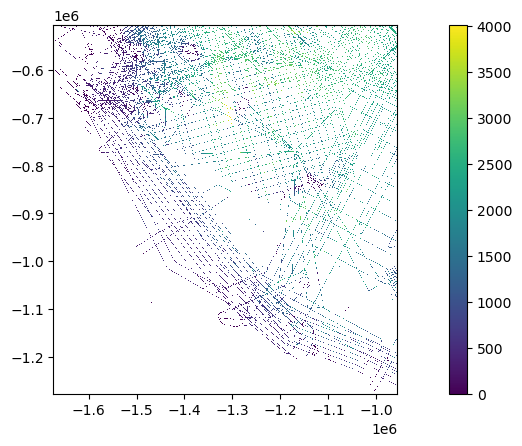

In [70]:
#plotting radar data from bedmap3
xmin_ant = -3333250
xmax_ant = 3333250
ymin_ant = -3333250
ymax_ant = 3333250

resolution = 500
xx_ant, yy_ant = np.meshgrid(np.arange(xmin_ant, xmax_ant + resolution, resolution), 
                     np.arange(ymin_ant, ymax_ant + resolution, resolution))

xmin_ind = np.where(xx_ant == xmin)[1][0]
xmax_ind = np.where(xx_ant == xmax)[1][0]
ymin_ind = np.where(yy_ant == ymin)[0][0]
ymax_ind = np.where(yy_ant == ymax)[0][0]

radar_thickness = np.load('Data/bedmap3_raw_thick_compilation.npy')
radar_thickness = np.flip(radar_thickness,axis=0)
radar_thickness = radar_thickness[ymin_ind:ymax_ind,xmin_ind:xmax_ind]

xx, yy = np.meshgrid(np.arange(xmin, xmax, resolution), 
                     np.arange(ymin, ymax, resolution))

plt.pcolormesh(xx,yy,radar_thickness)
plt.colorbar()
plt.axis('scaled')

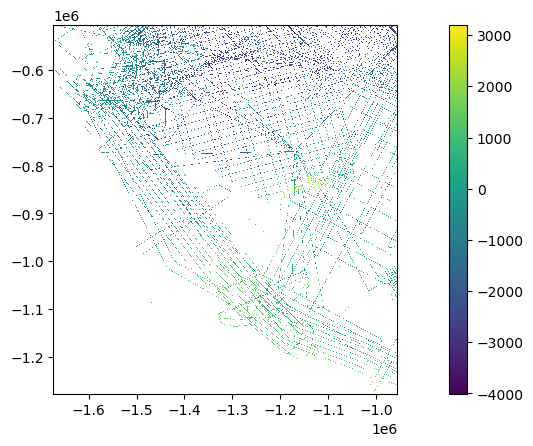

In [71]:
#adding radar bed data to ds
plt.pcolormesh(xx,yy,mbl['surface'].values.reshape(xx.shape) - radar_thickness)
plt.colorbar()
plt.axis('scaled')

mbl['radar_bed'] = mbl['surface'] - np.flipud(radar_thickness)

In [ ]:
ocean = mbl['mask'] == 0
mbl['cond_bed'] = xr.where(ocean, mbl['bed'], mbl['radar_bed'])

In [72]:
#showing test_area1 ds
mbl

<xarray.Dataset> Size: 64MB
Dimensions:    (y: 1544, x: 1436)
Coordinates:
  * y          (y) int32 6kB -505500 -506000 -506500 ... -1276500 -1277000
  * x          (x) int32 6kB -1673000 -1672500 -1672000 ... -956000 -955500
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 2MB ...
    firn       (y, x) float32 9MB ...
    surface    (y, x) float32 9MB 0.0 0.0 0.0 0.0 ... 0.5187 0.5145 2.515 3.44
    thickness  (y, x) float32 9MB ...
    bed        (y, x) float32 9MB ...
    errbed     (y, x) float32 9MB ...
    source     (y, x) int8 2MB ...
    dataid     (y, x) int8 2MB ...
    geoid      (y, x) int16 4MB ...
    radar_bed  (y, x) float32 9MB nan nan nan nan nan ... nan nan nan nan nan
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

In [73]:
df = mbl.to_dataframe().reset_index()



In [74]:
#converting ds to df for kriging and sgs


# grid data to 100 m resolution and remove coordinates with NaNs
res = 1000
df_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(df, 'x', 'y', 'cond_bed', res)
df_grid = df_grid[df_grid["Z"].isnull() == False]
df_grid = df_grid.rename(columns = {"Z": "Bed"})

# normal score transformation
data = df_grid['Bed'].values.reshape(-1,1)
nst_trans = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit(data)
df_grid['Nbed'] = nst_trans.transform(data) 

# compute experimental (isotropic) variogram
coords = df_grid[['X','Y']].values
values = df_grid['Nbed']

maxlag = 50000             # maximum range distance
n_lags = 70                # num of bins

V1 = skg.Variogram(coords, values, bin_func='even', n_lags=n_lags, 
                   maxlag=maxlag, normalize=False)

# use exponential variogram model
V1.model = 'Exponential'
V1.parameters

[np.float64(49999.999999999825), np.float64(0.7330244224224789), 0]

In [75]:
# ice surface normal score transformation
df_surface_grid, surface_grid_matrix, rows, cols = gs.Gridding.grid_data(df, 'x', 'y', 'surface', res) # grid data
df_surface_grid = df_surface_grid.rename(columns = {"Z": "Surface"}) # rename column for consistency

# normal score transformation
data_surf = df_surface_grid['Surface'].values.reshape(-1,1)
nst_trans_surf = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit(data_surf)
df_surface_grid['Nsurf'] = nst_trans_surf.transform(data_surf) 

In [76]:
# find co-located secondary data (this may take a few minutes)
df_colocated = gs.NearestNeighbor.find_colocated(df_grid, 'X', 'Y', 'Nbed', df_surface_grid, 'X', 'Y', 'Nsurf')

In [77]:
# compute correlation coefficient
rho12 = np.corrcoef(df_grid['Nbed'],df_colocated['colocated'])
corrcoef = rho12[0,1]
print('Correlation coefficient between bed and surface: ' + str(corrcoef))

Correlation coefficient between bed and surface: 0.025235907643860706


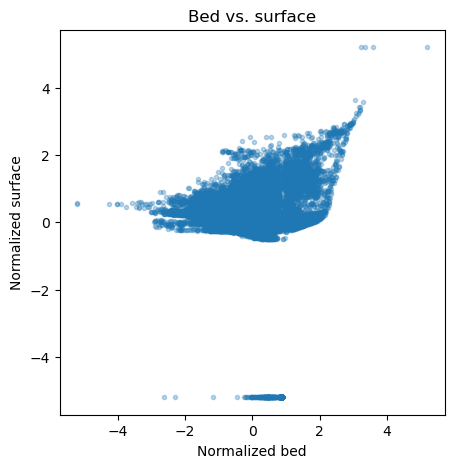

In [78]:
# scatter plot
plt.figure(figsize=(5,5))
im = plt.scatter(df_grid['Nbed'], df_colocated['colocated'], alpha=0.3, marker='.')
plt.title('Bed vs. surface')
plt.xlabel('Normalized bed')
plt.ylabel('Normalized surface')
plt.axis('scaled')
plt.show()

In [79]:
# define coordinate grid
xmin = np.min(df_grid['X']); xmax = np.max(df_grid['X'])     # min and max x values
ymin = np.min(df_grid['Y']); ymax = np.max(df_grid['Y'])     # min and max y values

Pred_grid_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, res)

In [80]:
# set variogram parameters
azimuth = 0
nugget = V1.parameters[2]

# the major and minor ranges are the same in this example because it is isotropic
major_range = V1.parameters[0]
minor_range = V1.parameters[0]
sill = V1.parameters[1] 
vtype = 'matern'
smoothness = 1
vario = [azimuth, nugget, major_range, minor_range, sill, vtype, smoothness]

k = 100         # number of neighboring data points used to estimate a given point 
rad = 100000     # 50 km search radius

est_cokrige, var_cokrige = gs.Interpolation.cokrige_mm1(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', 
                                     df_surface_grid, 'X', 'Y', 'Nsurf', k, vario, rad, corrcoef) 

  1%|          | 3394/547834 [04:25<11:50:02, 12.78it/s]


KeyboardInterrupt: 

In [63]:
# reverse normal score transformation
var_cokrige[var_cokrige < 0] = 0; # make sure variances are non-negative
std_cokrige = np.sqrt(var_cokrige) # convert to standard deviation (this should be done before back transforming!!!)

# reshape
est = est_cokrige.reshape(-1,1)
std = std_cokrige.reshape(-1,1)

# back transformation
cokrige_pred_trans = nst_trans.inverse_transform(est)
cokrige_std_trans = nst_trans.inverse_transform(std)
cokrige_std_trans = cokrige_std_trans - np.min(cokrige_std_trans)

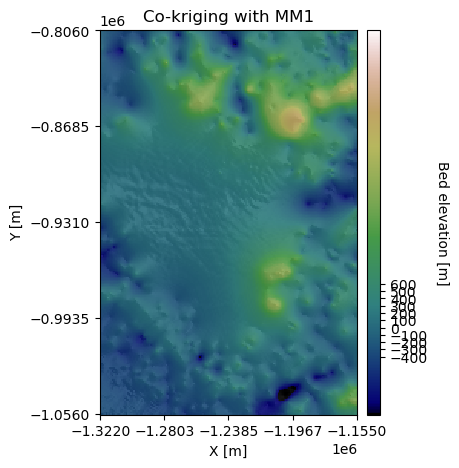

In [64]:
# make hillshade for visualizing
vmin = -1200; vmax = 4100
cols = len(np.unique(Pred_grid_xy[:, 0]))
rows = len(np.unique(Pred_grid_xy[:, 1]))
x_mat = Pred_grid_xy[:,0].reshape((rows, cols))
y_mat = Pred_grid_xy[:,1].reshape((rows, cols))
mat = cokrige_pred_trans.reshape((rows, cols))
xmin = Pred_grid_xy[:,0].min(); xmax = Pred_grid_xy[:,0].max()
ymin = Pred_grid_xy[:,1].min(); ymax = Pred_grid_xy[:,1].max()
    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Co-kriging with MM1')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

In [65]:
cosim = gs.Interpolation.cosim_mm1(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', 
                                     df_surface_grid, 'X', 'Y', 'Nsurf', k, vario, rad, corrcoef)

100%|██████████| 42168/42168 [12:33<00:00, 55.94it/s]


In [66]:
# reverse normal score transformation
sgs_cosim = cosim.reshape(-1,1)
cosim_trans = nst_trans.inverse_transform(sgs_cosim)

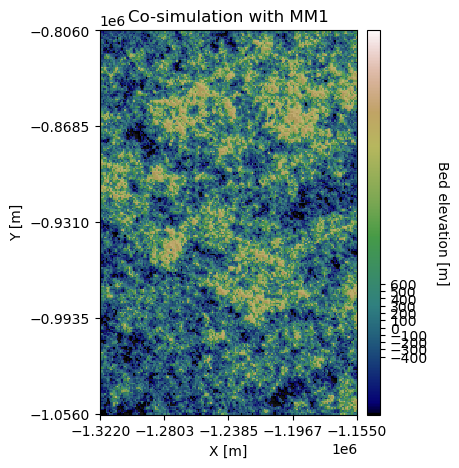

In [67]:
# make hillshade for visualizing
mat = cosim_trans.reshape((rows, cols))
vmin = -1200; vmax = 4100    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Co-simulation with MM1')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

In [21]:
# est_SK is the estimate and var_SK is the variance
est_SK, var_SK = gs.Interpolation.skrige(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', k, vario, rad)

100%|██████████| 20664/20664 [03:33<00:00, 96.60it/s] 


In [22]:
# reverse normal score transformation

var_SK[var_SK < 0] = 0      # make sure variances are non-negative
std_SK = np.sqrt(var_SK)    # convert to standard deviation before back transforming

# reshape
est = est_SK.reshape(-1,1)
std = std_SK.reshape(-1,1)

# back transformation
spred_trans = nst_trans.inverse_transform(est)
sstd_trans = nst_trans.inverse_transform(std)
sstd_trans = sstd_trans - np.min(sstd_trans)

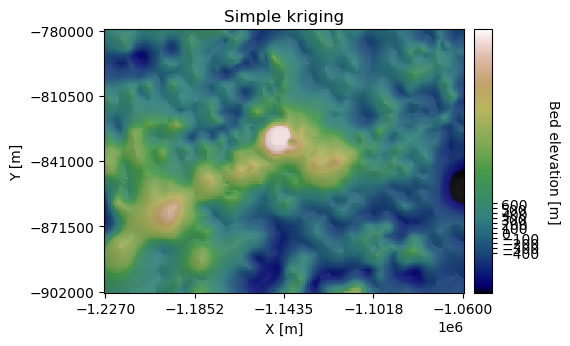

In [23]:
# make hillshade for visualizing
vmin = -1200; vmax = 4100
x_mat = Pred_grid_xy[:,0].reshape((rows, cols))
y_mat = Pred_grid_xy[:,1].reshape((rows, cols))
mat = spred_trans.reshape((rows, cols))
xmin = Pred_grid_xy[:,0].min(); xmax = Pred_grid_xy[:,0].max()
ymin = Pred_grid_xy[:,1].min(); ymax = Pred_grid_xy[:,1].max()
    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Simple kriging')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()


In [24]:
k = 100
est_OK, var_OK = gs.Interpolation.okrige(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', k, vario, rad) # estimation and variance

# reverse normal score transformation
var_OK[var_OK < 0] = 0; # make sure variances are non-negative
std_OK = np.sqrt(var_OK) # convert to standard deviation (this should be done before back transforming!!!)

# reshape
est = est_OK.reshape(-1,1)
std = std_OK.reshape(-1,1)

# back transformation
pred_trans = nst_trans.inverse_transform(est)
std_trans = nst_trans.inverse_transform(std)
std_trans = std_trans - np.min(std_trans)

100%|██████████| 20664/20664 [03:34<00:00, 96.23it/s] 


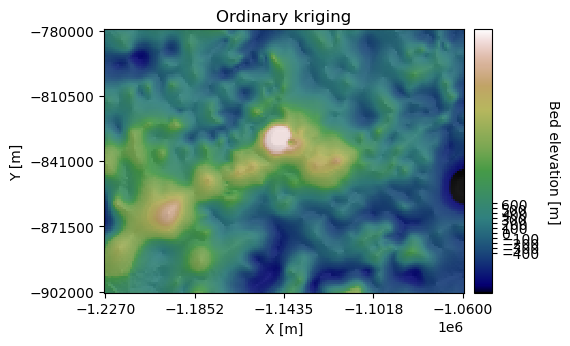

In [25]:
# make hillshade for visualizing
vmin = -1200; vmax = 4100
x_mat = Pred_grid_xy[:,0].reshape((rows, cols))
y_mat = Pred_grid_xy[:,1].reshape((rows, cols))
mat = pred_trans.reshape((rows, cols))
xmin = Pred_grid_xy[:,0].min(); xmax = Pred_grid_xy[:,0].max()
ymin = Pred_grid_xy[:,1].min(); ymax = Pred_grid_xy[:,1].max()
    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Ordinary kriging')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

In [26]:
sim = gs.Interpolation.okrige_sgs(Pred_grid_xy, df_grid, 'X', 'Y', 'Nbed', k, vario, rad)

100%|██████████| 20664/20664 [03:44<00:00, 92.23it/s] 


In [27]:
# reverse normal score transformation
sim1 = sim.reshape(-1,1)
sim_trans = nst_trans.inverse_transform(sim1)

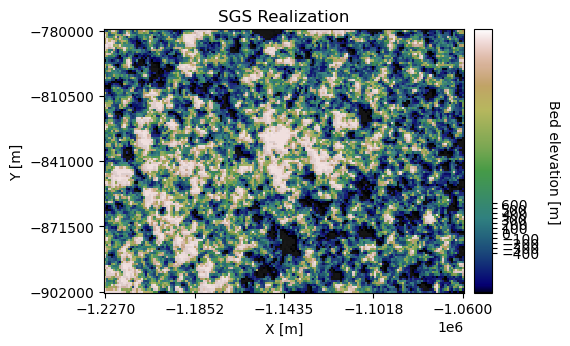

In [28]:
# make hillshade for visualizing
vmin = -1200; vmax = 4100
cols = len(np.unique(Pred_grid_xy[:, 0]))
rows = len(np.unique(Pred_grid_xy[:, 1]))
x_mat = Pred_grid_xy[:,0].reshape((rows, cols))
y_mat = Pred_grid_xy[:,1].reshape((rows, cols))
mat = sim_trans.reshape((rows, cols))
xmin = Pred_grid_xy[:,0].min(); xmax = Pred_grid_xy[:,0].max()
ymin = Pred_grid_xy[:,1].min(); ymax = Pred_grid_xy[:,1].max()
    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('SGS Realization')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

In [29]:
#split into 2 df, co sgs will be performed on upper
mask = (df["surface"] >= 2250) & (df["bed"] >= 2000)
upper = df[mask]
lower = df[~mask]

In [30]:
#verify df has split correctly
print("length of total df")
print(len(df))
print("length of upper df")
print(len(upper))
print("length of lower df")
print(len(lower))
print("head of upper df")
print(upper.head())
print("head of lower df")
print(lower.head())

length of total df
83148
length of upper df
3770
length of lower df
79378
head of upper df
            y        x mapping  mask       firn      surface   thickness  \
29913 -823500 -1142500     b''     2  21.363859  2251.831299   74.687500   
30244 -824000 -1146000     b''     2  21.144022  2254.125977  150.541992   
30245 -824000 -1145500     b''     2  21.189981  2278.846191  126.385986   
30246 -824000 -1145000     b''     2  21.235943  2295.760010  104.938232   
30247 -824000 -1144500     b''     2  21.281904  2320.552490   85.959961   

               bed  errbed  source  dataid  geoid  radar_bed  
29913  2177.143799    31.0       5       0    -37        NaN  
30244  2103.583984    30.0       5       0    -37        NaN  
30245  2152.460205    30.0       5       0    -37        NaN  
30246  2190.821777    30.0       3       0    -37        NaN  
30247  2234.592529    30.0       3       0    -37        NaN  
head of lower df
        y        x mapping  mask       firn      surface 

In [31]:
# Grid upper data
res = 1000  # resolution
upper_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(upper, 'x', 'y', 'radar_bed', res) # grid data
upper_grid = upper_grid[upper_grid["Z"].isnull() == False]  # remove coordinates with NaNs
upper_grid = upper_grid.rename(columns = {"Z": "Bed"}) # rename column for consistency

# normal score transformation
data = upper_grid['Bed'].values.reshape(-1,1)
nst_trans = QuantileTransformer(n_quantiles=100, output_distribution="normal").fit(data)
upper_grid['Nbed'] = nst_trans.transform(data) 

# compute experimental (isotropic) variogram
coords_upper = upper_grid[['X','Y']].values
values_upper = upper_grid['Nbed']
print("head of normalized upper grid")
print(upper_grid.head())

head of normalized upper grid
              X         Y          Sum  Count          Bed      Nbed
1105 -1191500.0 -863500.0  7944.177490    3.0  2648.059163  0.535083
1196 -1191500.0 -862500.0  2781.411377    1.0  2781.411377  0.828465
1934 -1181500.0 -854500.0  1818.260254    1.0  1818.260254 -2.085356
2115 -1182500.0 -852500.0  4113.277344    2.0  2056.638672 -1.786156
2409 -1161500.0 -849500.0  2061.145020    1.0  2061.145020 -1.593219


In [32]:
# Grid lower data
res = 1000  # resolution
lower_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(lower, 'x', 'y', 'radar_bed', res) # grid data
lower_grid = lower_grid[lower_grid["Z"].isnull() == False]  # remove coordinates with NaNs
lower_grid = lower_grid.rename(columns = {"Z": "Bed"}) # rename column for consistency

# normal score transformation
data = lower_grid['Bed'].values.reshape(-1,1)
nst_trans = QuantileTransformer(n_quantiles=100, output_distribution="normal").fit(data)
lower_grid['Nbed'] = nst_trans.transform(data) 

# compute experimental (isotropic) variogram
coords_lower = lower_grid[['X','Y']].values
values_lower = lower_grid['Nbed']
print("head of normalized lower grid")
print(lower_grid.head())
print(len(lower_grid))

head of normalized lower grid
             X         Y          Sum  Count         Bed      Nbed
39  -1188000.0 -902000.0  1364.733276    2.0  682.366638  0.666545
61  -1166000.0 -902000.0  -500.048584    2.0 -250.024292 -0.839075
69  -1158000.0 -902000.0 -1611.446777    2.0 -805.723389 -2.064845
83  -1144000.0 -902000.0   995.810425    2.0  497.905212  0.349152
101 -1126000.0 -902000.0  -551.447266    2.0 -275.723633 -0.900408
765


In [33]:
df_to_combine_upper = pd.DataFrame({
    'x': Pred_grid_xy[:, 0],
    'y': Pred_grid_xy[:, 1],
    'sim': cosim_trans.ravel()
})
print(df_to_combine_upper.head())
print(len(df_to_combine_upper))

           x         y          sim
0 -1227000.0 -780000.0  3911.472900
1 -1226000.0 -780000.0  3911.472900
2 -1225000.0 -780000.0  3899.079597
3 -1224000.0 -780000.0  3575.124089
4 -1223000.0 -780000.0  1786.766132
20664


In [34]:
upper_subset = df_to_combine_upper.merge(upper[['x', 'y']].drop_duplicates(), on=['x', 'y'], how='inner')

In [35]:
print(upper_subset.head())
print(len(upper_subset))

           x         y          sim
0 -1146000.0 -824000.0  2600.198213
1 -1145000.0 -824000.0  3901.692913
2 -1144000.0 -824000.0  3911.016503
3 -1143000.0 -824000.0  3878.961773
4 -1142000.0 -824000.0  2272.244657
941


In [36]:
df_to_combine_lower = pd.DataFrame({
    'x': Pred_grid_xy[:, 0],
    'y': Pred_grid_xy[:, 1],
    'sim': sim_trans.ravel()
})
print(df_to_combine_lower.head())
print(len(df_to_combine_lower))

           x         y          sim
0 -1227000.0 -780000.0  -146.418880
1 -1226000.0 -780000.0  -565.007106
2 -1225000.0 -780000.0  1656.513802
3 -1224000.0 -780000.0  3899.005932
4 -1223000.0 -780000.0  3909.164207
20664


In [37]:
lower_subset = df_to_combine_lower.merge(lower[['x', 'y']].drop_duplicates(), on=['x', 'y'], how='inner')

In [38]:
print(lower_subset.head())
print(len(lower_subset))

           x         y          sim
0 -1227000.0 -780000.0  -146.418880
1 -1226000.0 -780000.0  -565.007106
2 -1225000.0 -780000.0  1656.513802
3 -1224000.0 -780000.0  3899.005932
4 -1223000.0 -780000.0  3909.164207
19723


In [39]:
Pred_df = pd.DataFrame(Pred_grid_xy)
Pred_df = Pred_df.rename(columns={0:"x", 1:"y"})
print(Pred_df.head())

           x         y
0 -1227000.0 -780000.0
1 -1226000.0 -780000.0
2 -1225000.0 -780000.0
3 -1224000.0 -780000.0
4 -1223000.0 -780000.0


In [40]:
combined = pd.concat([lower_subset, upper_subset], ignore_index=True)
print(combined.head())
print(len(combined))

           x         y          sim
0 -1227000.0 -780000.0  -146.418880
1 -1226000.0 -780000.0  -565.007106
2 -1225000.0 -780000.0  1656.513802
3 -1224000.0 -780000.0  3899.005932
4 -1223000.0 -780000.0  3909.164207
20664


In [41]:
combined = pd.merge(Pred_df, combined, on = ["x", "y"], how = "inner")

In [42]:
print(combined.head())
print(combined.tail())

           x         y          sim
0 -1227000.0 -780000.0  -146.418880
1 -1226000.0 -780000.0  -565.007106
2 -1225000.0 -780000.0  1656.513802
3 -1224000.0 -780000.0  3899.005932
4 -1223000.0 -780000.0  3909.164207
               x         y          sim
20659 -1064000.0 -902000.0 -1257.154681
20660 -1063000.0 -902000.0 -1225.458525
20661 -1062000.0 -902000.0  -953.410564
20662 -1061000.0 -902000.0 -1239.433578
20663 -1060000.0 -902000.0 -1257.427775


In [43]:
combined_to_map = combined['sim'].to_numpy()

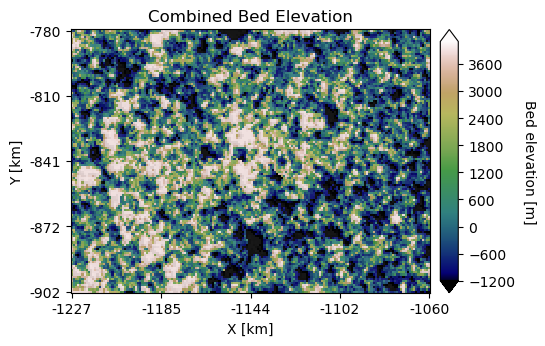

In [44]:
# make hillshade for visualizing
cols_sgs = len(np.unique(Pred_grid_xy[:, 0]))
rows_sgs = len(np.unique(Pred_grid_xy[:, 1]))
mat = combined_to_map.reshape((rows_sgs, cols_sgs))
x_mat = Pred_grid_xy[:,0].reshape((rows_sgs, cols_sgs))
y_mat = Pred_grid_xy[:,1].reshape((rows_sgs, cols_sgs))

vmin = -1200; vmax = 4100    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Combined Bed Elevation')
ax.xaxis.set_major_formatter(lambda x, pos: f'{x/1000:.0f}')
ax.yaxis.set_major_formatter(lambda y, pos: f'{y/1000:.0f}')
plt.xlabel('X [km]'); plt.ylabel('Y [km]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.arange(-1200, 4101, 600), cax=cax, extend="both")
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()